# Verified Pick–Cross–Place: Build the Expert, Then Teach a Learner

**Student edition**

**Expert-first lab · student/solutions editions share exactly the same cell order**

You already built the simulator. We will not repeat it. We will extend its task contract, then
build the expert from geometric primitives, transition guards, memory, recovery, data collection,
a demonstration database, hybrid behavior cloning, and strict closed-loop evaluation.

The mission is intentionally harder than ordinary `PandaPickAndPlace-v3`: carry an orange cube
over a physical blue barrier, place it on the opposite side, open the fingers, retreat the arm,
and prove that the released cube remains stable for 12 consecutive steps.


In [1]:
from __future__ import annotations

import json
import random
import sqlite3
import sys
import tempfile
from collections import Counter
from copy import deepcopy
from dataclasses import dataclass, field
from enum import Enum
from math import sqrt
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import Image as NotebookImage, display
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Locate the repository whether Jupyter starts in the root or notebooks/.
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(path for path in candidates if (path / "src" / "ilgrasp").exists())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from ilgrasp.data import TrainingData
from ilgrasp.sim import Episode, VerifiedPlacementEnv
from ilgrasp.visualization import record_verified_expert_gif

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.titleweight": "bold"})
np.set_printoptions(precision=3, suppress=True)

QUICK_MODE = True
EXPERT_BENCHMARK_EPISODES = 12 if QUICK_MODE else 100
TARGET_DEMOS = 24 if QUICK_MODE else 100
TRAIN_EPOCHS = 45 if QUICK_MODE else 100
EVAL_EPISODES = 12 if QUICK_MODE else 100
tutorial_dir = Path(tempfile.mkdtemp(prefix="verified_expert_lab_"))
print("project:", PROJECT_ROOT)
print("temporary run directory:", tutorial_dir)


project: /Users/aayushhegde/Documents/ALL CODING HERE/imitation-learning-grasp
temporary run directory: /var/folders/0k/h6cq9ntd0jg2tl0vt221vwbc0000gn/T/verified_expert_lab_vyq6jpgl


## 0. Begin with the finished use case

The animation below is generated from the real PyBullet simulator—not a hand-drawn robot. It has
two cameras, the complete 13-phase timeline, a live completion certificate, native versus strict
success indicators, and physical telemetry. Watch what happens **after** `NATIVE HIT` becomes
yellow. The expert must still open, retreat, and verify stability before `VERIFIED` turns green.


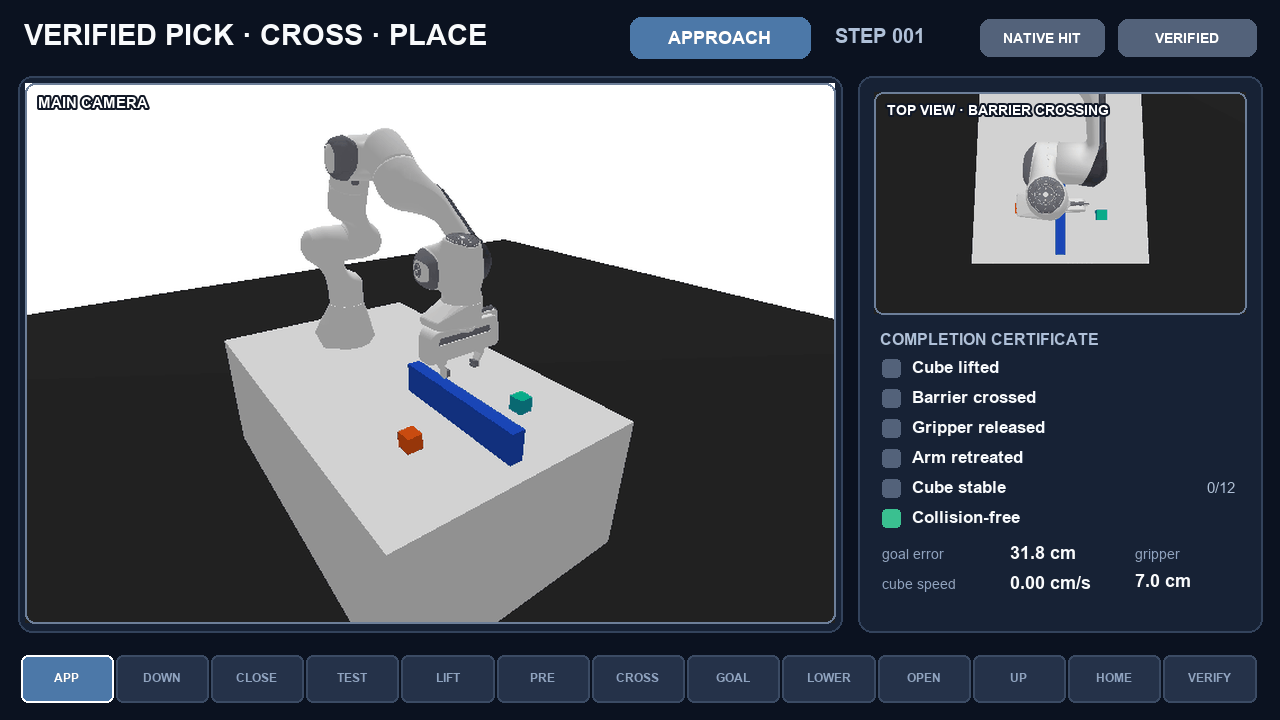

In [2]:
animation_path = PROJECT_ROOT / "notebooks" / "assets" / "verified_pick_cross_place.gif"
if not animation_path.exists():
    record_verified_expert_gif(animation_path, seed=7)
display(NotebookImage(filename=str(animation_path)))


## 1. The provided task adapter: same simulator, stricter meaning of success

Panda Gym's native task stops when the cube first enters a 5 cm sphere around the goal. It may
still be held in a closed gripper—and 70% of native goals can be suspended in mid-air. That metric
is not a completed placement.

`VerifiedPlacementEnv` is a thin adapter around the simulator you already know. It preserves the
exact observation `(22,)` and action `(4,)` contracts. It fixes both object and goal on the table,
places them on opposite sides of a fixed barrier, disables native early termination, and exposes
an independent physical certificate:

```text
lifted ∧ crossed ∧ released ∧ retreated ∧ stable_12 ∧ collision_free
```

A fixed obstacle keeps the challenge observable without changing the 22-dimensional state. A
randomly moving obstacle would have to be added to the learner's observation.


In [3]:
counter_env = VerifiedPlacementEnv()
obs, info = counter_env.reset(seed=2)
goal = np.asarray(counter_env.raw_obs["desired_goal"])
base = counter_env.unwrapped
base.sim.set_base_pose("object", goal, np.array([0.0, 0.0, 0.0, 1.0]))
object_id = base.sim._bodies_idx["object"]
base.sim.physics_client.resetBaseVelocity(
    object_id, linearVelocity=[0, 0, 0], angularVelocity=[0, 0, 0]
)
_, _, terminated, _, info = counter_env.step(np.zeros(4, dtype=np.float32))
print({key: info[key] for key in [
    "native_success", "strict_success", "ever_lifted",
    "ever_released", "retreated", "stable_steps"
]})
assert info["native_success"] and not terminated and not info["strict_success"]
counter_env.close()


pybullet build time: Jul 10 2026 00:10:09


argv[0]=--background_color_red=0.8745098114013672
argv[1]=--background_color_green=0.21176470816135406
argv[2]=--background_color_blue=0.1764705926179886
{'native_success': True, 'strict_success': False, 'ever_lifted': False, 'ever_released': False, 'retreated': False, 'stable_steps': 0}


## 2. E01 — Parse simulator state into concepts

Neural networks like vectors; experts need concepts. `RobotState` gives names to the slices used by
geometry. Return copies so later simulator updates cannot silently mutate saved states.

Main observation layout: `ee 0:3`, `finger width 6`, `object 7:10`, object linear velocity
`13:16`, angular velocity `16:19`; the desired goal is a separate three-vector.


In [4]:
@dataclass(frozen=True)
class RobotState:
    ee: np.ndarray
    gripper_width: float  
    obj: np.ndarray
    obj_velocity: np.ndarray
    obj_angular_velocity: np.ndarray
    goal: np.ndarray

    @classmethod
    def from_raw_obs(cls, raw_obs: dict[str, np.ndarray]) -> "RobotState":
        """E01: validate and decode one Panda observation."""
        main = np.asarray(raw_obs["observation"], dtype=np.float32) 
        goal = np.asarray(raw_obs["desired_goal"], dtype=np.float32)
        if main.shape != (19,) or goal.shape != (3,):
            raise ValueError(f"Unexpected observation shapes: {main.shape}, {goal.shape}")
        if not np.all(np.isfinite(main)) or not np.all(np.isfinite(goal)):
            raise ValueError("Observation contains non-finite values.")
        return cls(
            ee=main[0:3].copy(),
            gripper_width=float(main[6]),
            obj=main[7:10].copy(),
            obj_velocity=main[10:13].copy(),
            obj_angular_velocity=main[13:16].copy(),
            goal=goal.copy(),
        )

In [5]:
test_env = VerifiedPlacementEnv()
test_env.reset(seed=5)
decoded = RobotState.from_raw_obs(test_env.raw_obs)
assert decoded.ee.shape == decoded.obj.shape == decoded.goal.shape == (3,)
original = test_env.raw_obs["observation"][0]
decoded.ee[0] += 10
assert test_env.raw_obs["observation"][0] == original, "E01 must return copies"
test_env.close()
print("E01 checks passed")


argv[0]=--background_color_red=0.8745098114013672
argv[1]=--background_color_green=0.21176470816135406
argv[2]=--background_color_blue=0.1764705926179886
E01 checks passed


## 3. E02 — One bounded geometric controller

Every movement phase uses the same proportional controller:

$$a_{xyz}=\mathrm{clip}(k(p_{target}-p_{ee}),-1,1).$$

A large error saturates at full speed; a small error produces a gentle correction. The fourth
action is the gripper command: `+1` opens and `-1` closes.


In [6]:
def bounded_move_action(
    ee: np.ndarray, target: np.ndarray, gripper: float, gain: float = 20.0
) -> np.ndarray:
    """E02: return [dx, dy, dz, gripper] as clipped float32."""
    ee = np.asarray(ee, dtype=np.float32)
    target = np.asarray(target, dtype=np.float32)
    if ee.shape != (3,) or target.shape != (3,):
        raise ValueError(f"Expected ee and target to be shape (3,), got {ee.shape} and {target.shape}")
    if not np.all(np.isfinite(ee)) or not np.all(np.isfinite(target)):
        raise ValueError("ee and target contain non-finite values.")

    xyz = np.clip(gain * (target - ee), -1.0, 1.0)
    return np.r_[xyz, np.clip(gripper, -1.0, 1.0)].astype(np.float32)


In [7]:
a = bounded_move_action(np.zeros(3), np.array([1.0, -0.01, 0.02]), -2.0)
np.testing.assert_allclose(a, [1.0, -0.2, 0.4, -1.0], atol=1e-6)
assert a.dtype == np.float32 and a.shape == (4,)
print("E02 checks passed")


E02 checks passed


## 4. Build a 13-phase expert from decisions and guards

We separate four ideas:

- `ExpertPhase`: named discrete modes;
- `ExpertConfig`: tunable numbers, never hidden magic constants;
- `ExpertMemory`: facts remembered across time;
- `ControlDecision`: the current target and gripper command.

The controller decision answers “what should I do now?” A transition guard separately answers
“when may I move to the next phase?” This separation makes the expert testable.


In [8]:
class ExpertPhase(str, Enum):
    APPROACH = "approach"
    DESCEND = "descend"
    CLOSE = "close"
    TEST_GRASP = "test_grasp"
    LIFT_CLEAR = "lift_clear"
    PRE_CROSS = "pre_cross"
    CROSS_BARRIER = "cross_barrier"
    ABOVE_GOAL = "above_goal"
    LOWER = "lower"
    OPEN = "open"
    RETREAT_UP = "retreat_up"
    RETREAT_HOME = "retreat_home"
    VERIFY = "verify"


@dataclass(frozen=True)
class ExpertConfig:
    hover_height: float = 0.12
    grasp_offset: float = 0.015
    test_lift: float = 0.045
    safe_z: float = 0.17
    pre_cross_y: float = -0.075
    post_cross_y: float = 0.075
    position_tolerance: float = 0.018
    place_tolerance: float = 0.035
    gain: float = 20.0
    close_steps: int = 10
    open_steps: int = 12
    test_timeout: int = 18
    home: tuple[float, float, float] = (0.04, 0.0, 0.20)


@dataclass
class ExpertMemory:
    phase: ExpertPhase = ExpertPhase.APPROACH
    phase_steps: int = 0
    retries: int = 0
    grasp_offset: np.ndarray = field(default_factory=lambda: np.array([0.0, 0.0, 0.015]))
    grasp_target: np.ndarray | None = None
    release_target: np.ndarray | None = None


@dataclass(frozen=True)
class ControlDecision:
    target: np.ndarray
    gripper: float


### E03–E05 — Write the phase targets

These three functions cover pick, transport, and finish. They contain no transition logic. A
frozen absolute `grasp_target` is essential while closing: following the moving cube can push it
diagonally instead of grasping it.


In [9]:
def pick_decision(
    phase: ExpertPhase, state: RobotState, memory: ExpertMemory, cfg: ExpertConfig
) -> ControlDecision:
    """E03: APPROACH, DESCEND, CLOSE, TEST_GRASP."""
    if phase is ExpertPhase.APPROACH:
        target = state.obj + np.array([0.0, 0.0, cfg.hover_height])
        return ControlDecision(target=target, gripper=1.0)

    if phase is ExpertPhase.DESCEND:
        target = state.obj + memory.grasp_offset
        return ControlDecision(target=target, gripper=1.0)

    if memory.grasp_target is None:
        memory.grasp_target = state.obj + memory.grasp_offset

    if phase is ExpertPhase.CLOSE:
        return ControlDecision(target=memory.grasp_target, gripper=-1.0)

    # TEST_GRASP
    target = memory.grasp_target + np.array([0.0, 0.0, cfg.test_lift])
    return ControlDecision(target=target, gripper=-1.0)

In [10]:
def transport_decision(
    phase: ExpertPhase, state: RobotState, memory: ExpertMemory, cfg: ExpertConfig
) -> ControlDecision:
    """E04: LIFT_CLEAR, PRE_CROSS, CROSS_BARRIER, ABOVE_GOAL."""
    if phase is ExpertPhase.LIFT_CLEAR:
        target = np.array([state.ee[0], state.ee[1], cfg.safe_z])
        return ControlDecision(target=target, gripper=-1.0)

    if phase is ExpertPhase.PRE_CROSS:
        target = np.array([state.goal[0], cfg.pre_cross_y, cfg.safe_z])
        return ControlDecision(target=target, gripper=-1.0)

    if phase is ExpertPhase.CROSS_BARRIER:
        target = np.array([state.goal[0], cfg.post_cross_y, cfg.safe_z])
        return ControlDecision(target=target, gripper=-1.0)

    # ABOVE_GOAL
    target = np.array([state.goal[0], state.goal[1], cfg.safe_z])
    return ControlDecision(target=target, gripper=-1.0)

In [11]:
def finish_decision(
    phase: ExpertPhase, state: RobotState, memory: ExpertMemory, cfg: ExpertConfig
) -> ControlDecision:
    """E05: LOWER, OPEN, RETREAT_UP, RETREAT_HOME, VERIFY."""
    if phase is ExpertPhase.LOWER:
        target = state.goal + memory.grasp_offset
        return ControlDecision(target=target, gripper=-1.0)

    if memory.release_target is None:
        memory.release_target = state.goal + memory.grasp_offset

    if phase is ExpertPhase.OPEN:
        return ControlDecision(target=memory.release_target, gripper=1.0)

    if phase is ExpertPhase.RETREAT_UP:
        target = np.array([state.ee[0], state.ee[1], cfg.safe_z])
        return ControlDecision(target=target, gripper=1.0)

    # RETREAT_HOME and VERIFY
    return ControlDecision(target=np.array(cfg.home), gripper=1.0)

In [12]:
PICK_PHASES = {
    ExpertPhase.APPROACH, ExpertPhase.DESCEND,
    ExpertPhase.CLOSE, ExpertPhase.TEST_GRASP,
}
TRANSPORT_PHASES = {
    ExpertPhase.LIFT_CLEAR, ExpertPhase.PRE_CROSS,
    ExpertPhase.CROSS_BARRIER, ExpertPhase.ABOVE_GOAL,
}

def controller_decision(
    state: RobotState, memory: ExpertMemory, cfg: ExpertConfig
) -> ControlDecision:
    if memory.phase in PICK_PHASES:
        return pick_decision(memory.phase, state, memory, cfg)
    if memory.phase in TRANSPORT_PHASES:
        return transport_decision(memory.phase, state, memory, cfg)
    return finish_decision(memory.phase, state, memory, cfg)

def arrived(a: np.ndarray, b: np.ndarray, tolerance: float) -> bool:
    return bool(np.linalg.norm(a - b) < tolerance)


### E06 — Transition guards and recovery

A phase changes only after a measurable guard succeeds. `TEST_GRASP` is the recovery branch: if
the cube does not rise with the hand before timeout, retry from `APPROACH` instead of blindly
carrying an empty gripper.


In [13]:
GRASP_HOLD_TOLERANCE = 0.06   # cube must hang within 6cm below the hand
MIN_GRASP_WIDTH = 0.015       # fingers stopped on something, not closed empty


def _cube_is_held(state: RobotState) -> bool:
    """Two independent signals: cube hangs below the hand, and fingers stopped on it."""
    vertical_gap = state.ee[2] - state.obj[2]
    below_hand = 0.0 < vertical_gap < GRASP_HOLD_TOLERANCE
    fingers_on_object = state.gripper_width > MIN_GRASP_WIDTH
    return below_hand and fingers_on_object


def advance_phase(state: RobotState, memory: ExpertMemory, cfg: ExpertConfig) -> None:
    """E06: mutate memory only when the current phase guard is satisfied."""
    phase = memory.phase
    decision = controller_decision(state, memory, cfg)
    at_target = arrived(state.ee, decision.target, cfg.position_tolerance)

    next_phase = None

    if phase is ExpertPhase.APPROACH:
        if at_target:
            next_phase = ExpertPhase.DESCEND

    elif phase is ExpertPhase.DESCEND:
        if at_target:
            next_phase = ExpertPhase.CLOSE

    elif phase is ExpertPhase.CLOSE:
        if memory.phase_steps >= cfg.close_steps:
            next_phase = ExpertPhase.TEST_GRASP

    elif phase is ExpertPhase.TEST_GRASP:
        if _cube_is_held(state):
            next_phase = ExpertPhase.LIFT_CLEAR
        elif memory.phase_steps >= cfg.test_timeout:
            memory.retries += 1
            memory.grasp_target = None
            next_phase = ExpertPhase.APPROACH

    elif phase is ExpertPhase.LIFT_CLEAR:
        if at_target:
            next_phase = ExpertPhase.PRE_CROSS

    elif phase is ExpertPhase.PRE_CROSS:
        if at_target:
            next_phase = ExpertPhase.CROSS_BARRIER

    elif phase is ExpertPhase.CROSS_BARRIER:
        if at_target:
            next_phase = ExpertPhase.ABOVE_GOAL

    elif phase is ExpertPhase.ABOVE_GOAL:
        if at_target:
            next_phase = ExpertPhase.LOWER

    elif phase is ExpertPhase.LOWER:
        if arrived(state.ee, decision.target, cfg.place_tolerance):
            next_phase = ExpertPhase.OPEN

    elif phase is ExpertPhase.OPEN:
        if memory.phase_steps >= cfg.open_steps:
            next_phase = ExpertPhase.RETREAT_UP

    elif phase is ExpertPhase.RETREAT_UP:
        if at_target:
            next_phase = ExpertPhase.RETREAT_HOME

    elif phase is ExpertPhase.RETREAT_HOME:
        if at_target:
            next_phase = ExpertPhase.VERIFY

    # VERIFY is terminal — the environment ends the episode, not the expert

    if next_phase is not None:
        memory.phase = next_phase
        memory.phase_steps = 0

### E07 — Assemble the expert

`act` should be boring: decode state, advance a timestep counter, ask for one decision, convert it
to an action, then evaluate transition guards. Small orchestration methods are easier to trust.


In [14]:
class BarrierPickPlaceExpert:
    def __init__(self, config: ExpertConfig | None = None) -> None:
        self.config = config or ExpertConfig()
        self.reset()

    def reset(self) -> None:
        self.memory = ExpertMemory()
        self.last_target: np.ndarray | None = None

    @property
    def phase(self) -> ExpertPhase:
        return self.memory.phase

    def act(self, raw_obs: dict[str, np.ndarray]) -> np.ndarray:
        state = RobotState.from_raw_obs(raw_obs)
        self.memory.phase_steps += 1
        decision = controller_decision(state, self.memory, self.config)
        action = bounded_move_action(
            state.ee, decision.target, decision.gripper, self.config.gain
        )
        advance_phase(state, self.memory, self.config)
        self.last_target = decision.target
        return action


In [15]:
expert_env = VerifiedPlacementEnv()
expert = BarrierPickPlaceExpert()
obs, _ = expert_env.reset(seed=7)
expert.reset()
phases, final_info = [], {}
for _ in range(expert_env.config.max_episode_steps):
    phases.append(expert.phase.value)
    action = expert.act(expert_env.raw_obs)
    obs, _, terminated, truncated, final_info = expert_env.step(action)
    if terminated or truncated:
        break
required_phases = {phase.value for phase in ExpertPhase}
print({
    "strict_success": final_info["strict_success"],
    "steps": final_info["step"],
    "retries": expert.memory.retries,
    "phases_seen": len(set(phases)),
    "certificate": {k: final_info[k] for k in [
        "ever_lifted", "ever_crossed", "ever_released",
        "retreated", "stable_steps", "collision_free"
    ]},
})
assert final_info["strict_success"]
assert required_phases.issubset(set(phases))
expert_env.close()


argv[0]=--background_color_red=0.8745098114013672
argv[1]=--background_color_green=0.21176470816135406
argv[2]=--background_color_blue=0.1764705926179886
{'strict_success': True, 'steps': 70, 'retries': 0, 'phases_seen': 13, 'certificate': {'ever_lifted': True, 'ever_crossed': True, 'ever_released': True, 'retreated': True, 'stable_steps': 12, 'collision_free': True}}


## 5. E08 — Collect an aligned expert trace

Row `t` must mean: “from observation `o_t`, the expert selected action `a_t` in phase `p_t`."
Record all three **before** stepping. Store task information after the step as the outcome of that
action. This alignment rule prevents a subtle one-step label shift.


In [16]:
@dataclass
class ExpertTrace:
    observations: np.ndarray
    actions: np.ndarray
    rewards: np.ndarray
    phases: list[str]
    infos: list[dict[str, Any]]
    seed: int

    @property
    def success(self) -> bool:
        return bool(self.infos[-1]["strict_success"])

    def as_episode(self) -> Episode:
        return Episode(
            self.observations,
            self.actions,
            self.rewards,
            self.success,
            seed=self.seed,
            usable_for_training=self.success and self.infos[-1]["collision_free"],
            phases=self.phases,
        )


In [17]:
def collect_trace(env: VerifiedPlacementEnv, expert: BarrierPickPlaceExpert, seed: int) -> ExpertTrace:
    """E08: collect one complete strict task trace without an off-by-one error."""
    obs, _ = env.reset(seed=seed)
    expert.reset()

    observations, actions, rewards, phases, infos = [], [], [], [], []

    for _ in range(env.config.max_episode_steps):
        # record BEFORE stepping: this is the state the expert acted from
        observations.append(obs)
        phases.append(expert.phase.value)
        action = expert.act(env.raw_obs)
        actions.append(action.copy())

        obs, reward, terminated, truncated, info = env.step(action)

        # record AFTER stepping: consequences of that action
        rewards.append(reward)
        infos.append(info)

        if terminated or truncated:
            break

    return ExpertTrace(
        observations=np.asarray(observations, dtype=np.float32),
        actions=np.asarray(actions, dtype=np.float32),
        rewards=np.asarray(rewards, dtype=np.float32),
        phases=phases,
        infos=infos,
        seed=seed,
    )

## 6. E09 — Store strict evidence, not just a success bit

The database keeps failed traces for diagnosis but the training query selects only
`strict_success=1 AND collision_free=1`. `native_success_seen` is stored separately so nobody can
accidentally substitute the easier benchmark metric later.


In [18]:
class VerifiedDemoStore:
    def __init__(self, path: Path) -> None:
        self.connection = sqlite3.connect(path)
        self.connection.executescript("""
            CREATE TABLE episodes (
                episode_id INTEGER PRIMARY KEY AUTOINCREMENT,
                seed INTEGER NOT NULL,
                strict_success INTEGER NOT NULL,
                native_success_seen INTEGER NOT NULL,
                collision_free INTEGER NOT NULL,
                stable_steps INTEGER NOT NULL,
                n_steps INTEGER NOT NULL
            );
            CREATE TABLE steps (
                episode_id INTEGER NOT NULL,
                step INTEGER NOT NULL,
                observation TEXT NOT NULL,
                action TEXT NOT NULL,
                phase TEXT NOT NULL,
                PRIMARY KEY (episode_id, step),
                FOREIGN KEY (episode_id) REFERENCES episodes(episode_id)
            );
        """)

    def save(self, trace: ExpertTrace) -> int:
        final = trace.infos[-1]
        with self.connection:
            cursor = self.connection.execute("""
                INSERT INTO episodes(
                    seed, strict_success, native_success_seen,
                    collision_free, stable_steps, n_steps
                ) VALUES (?, ?, ?, ?, ?, ?)
            """, (
                trace.seed, int(trace.success), int(final["native_success_seen"]),
                int(final["collision_free"]), int(final["stable_steps"]), len(trace.actions)
            ))
            episode_id = int(cursor.lastrowid)
            self.connection.executemany("""
                INSERT INTO steps(episode_id, step, observation, action, phase)
                VALUES (?, ?, ?, ?, ?)
            """, [
                (
                    episode_id, i,
                    json.dumps(obs.tolist(), separators=(",", ":")),
                    json.dumps(action.tolist(), separators=(",", ":")),
                    phase,
                )
                for i, (obs, action, phase) in enumerate(zip(
                    trace.observations, trace.actions, trace.phases
                ))
            ])
        return episode_id

    def close(self) -> None:
        self.connection.close()


In [19]:
def load_verified_training_data(
    connection: sqlite3.Connection, max_episodes: int
) -> TrainingData:
    """E09: load steps from at most N strict, collision-free episodes."""
    rows = connection.execute(
        """
        WITH chosen AS (
            SELECT episode_id
            FROM episodes
            WHERE strict_success = 1 AND collision_free = 1
            ORDER BY episode_id
            LIMIT ?
        )
        SELECT s.episode_id, s.observation, s.action, s.phase
        FROM steps AS s
        JOIN chosen AS c ON c.episode_id = s.episode_id
        ORDER BY s.episode_id, s.step
        """,
        (max_episodes,),
    ).fetchall()

    if not rows:
        raise ValueError("No strict, collision-free episodes in the database.")

    episode_ids, observations, actions, phases = [], [], [], []
    for episode_id, observation_json, action_json, phase in rows:
        episode_ids.append(episode_id)
        observations.append(json.loads(observation_json))
        actions.append(json.loads(action_json))
        phases.append(phase)

    return TrainingData(
        observations=np.asarray(observations, dtype=np.float32),
        actions=np.asarray(actions, dtype=np.float32),
        episode_ids=np.asarray(episode_ids, dtype=np.int64),
        phases=np.asarray(phases),
    )

In [20]:
store = VerifiedDemoStore(tutorial_dir / "verified_demos.sqlite")
data_env = VerifiedPlacementEnv()
for seed in range(TARGET_DEMOS):
    trace = collect_trace(data_env, BarrierPickPlaceExpert(), seed)
    store.save(trace)
data_env.close()
data = load_verified_training_data(store.connection, TARGET_DEMOS)
episode_rows = store.connection.execute("""
    SELECT COUNT(*), SUM(strict_success), SUM(native_success_seen), SUM(collision_free)
    FROM episodes
""").fetchone()
print({
    "episodes / strict / native-hit / collision-free": episode_rows,
    "observations": data.observations.shape,
    "actions": data.actions.shape,
})


argv[0]=--background_color_red=0.8745098114013672
argv[1]=--background_color_green=0.21176470816135406
argv[2]=--background_color_blue=0.1764705926179886
{'episodes / strict / native-hit / collision-free': (24, 23, 23, 24), 'observations': (1685, 22), 'actions': (1685, 4)}


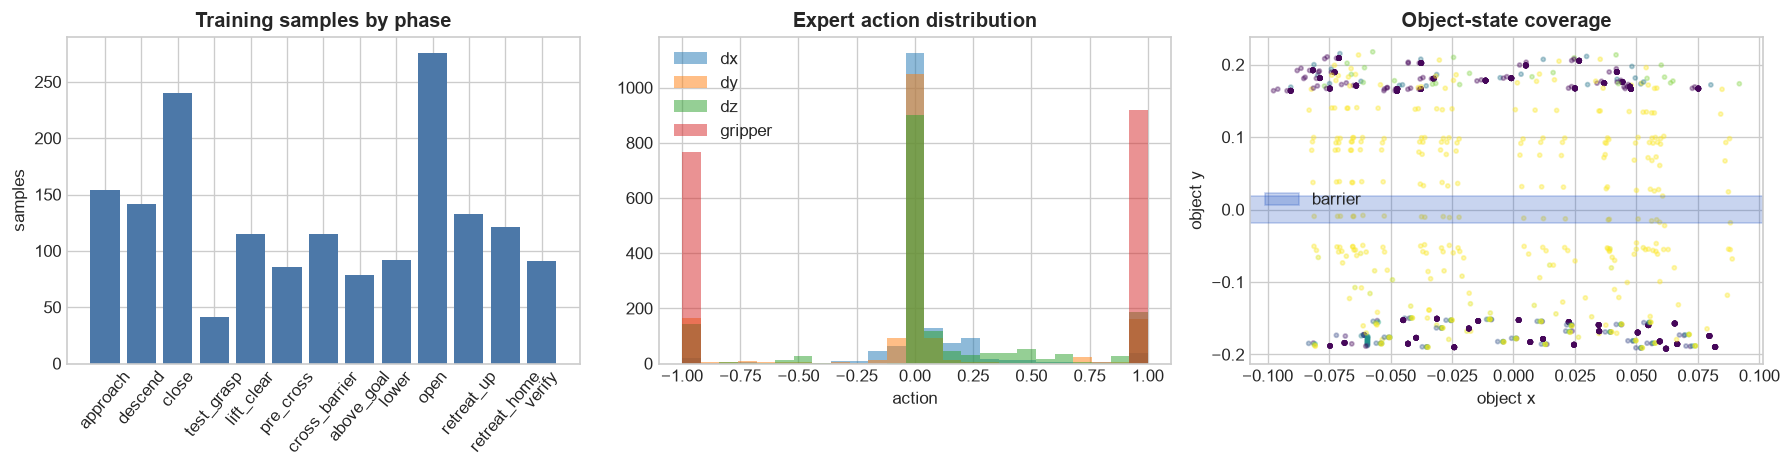

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
counts = Counter(data.phases)
axes[0].bar(counts.keys(), counts.values(), color="#4C78A8")
axes[0].set(title="Training samples by phase", ylabel="samples")
axes[0].tick_params(axis="x", rotation=50)
for j, name in enumerate(["dx", "dy", "dz", "gripper"]):
    axes[1].hist(data.actions[:, j], bins=25, alpha=0.5, label=name)
axes[1].set(title="Expert action distribution", xlabel="action")
axes[1].legend()
axes[2].scatter(
    data.observations[:, 7], data.observations[:, 8],
    c=data.observations[:, 9], s=6, alpha=0.35, cmap="viridis"
)
axes[2].axhspan(-0.018, 0.018, color="#2455C3", alpha=0.25, label="barrier")
axes[2].set(title="Object-state coverage", xlabel="object x", ylabel="object y")
axes[2].legend()
plt.tight_layout()
plt.show()


## 7. E10–E11 — Learning mechanism: preserve episodes and gripper modes

The student already knows MLPs, so our focus is the interface. Adjacent timesteps from one
trajectory must never be split across train and validation. For the output, ordinary four-channel
MSE can average `open=+1` and `close=-1` toward a useless zero. We use a hybrid head:

- xyz motion: bounded regression with Smooth L1;
- gripper: binary open/close classification with BCE.


In [22]:
def split_episode_ids(
    episode_ids: np.ndarray, validation_fraction: float, seed: int
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """E10: return train_mask, val_mask, train_ids, val_ids."""
    unique_ids = np.unique(episode_ids)
    if unique_ids.size < 2:
        raise ValueError("Need at least two episodes to form a split.")

    shuffled = np.random.default_rng(seed).permutation(unique_ids)

    n_val = int(round(validation_fraction * unique_ids.size))
    n_val = min(max(n_val, 1), unique_ids.size - 1)   # both sides stay non-empty

    val_ids = np.sort(shuffled[:n_val])
    train_ids = np.sort(shuffled[n_val:])

    val_mask = np.isin(episode_ids, val_ids)
    train_mask = ~val_mask
    return train_mask, val_mask, train_ids, val_ids

In [23]:
def hybrid_bc_loss(
    motion_prediction: torch.Tensor,
    gripper_logit: torch.Tensor,
    expert_actions: torch.Tensor,
) -> torch.Tensor:
    """E11: SmoothL1(xyz) + 0.35 * BCE(open/close)."""
    motion_loss = F.smooth_l1_loss(motion_prediction, expert_actions[:, :3])

    gripper_target = (expert_actions[:, 3:4] > 0).to(motion_prediction.dtype)
    gripper_loss = F.binary_cross_entropy_with_logits(gripper_logit, gripper_target)

    return motion_loss + 0.35 * gripper_loss

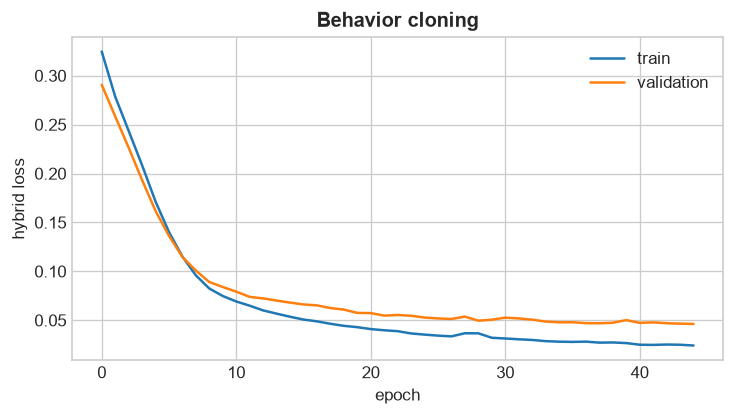

In [24]:
class HybridPolicy(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Linear(22, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
        )
        self.motion_head = nn.Sequential(nn.Linear(128, 3), nn.Tanh())
        self.gripper_head = nn.Linear(128, 1)
        self.register_buffer("obs_mean", torch.zeros(22))
        self.register_buffer("obs_std", torch.ones(22))

    def set_normalization(self, observations: np.ndarray) -> None:
        x = torch.as_tensor(observations, dtype=torch.float32)
        self.obs_mean.copy_(x.mean(0))
        self.obs_std.copy_(x.std(0, unbiased=False).clamp_min(1e-6))

    def forward(self, observations: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        hidden = self.trunk((observations - self.obs_mean) / self.obs_std)
        return self.motion_head(hidden), self.gripper_head(hidden)


class HybridNumpyPolicy:
    def __init__(self, model: HybridPolicy) -> None:
        self.model = model.eval()

    def __call__(self, observation: np.ndarray) -> np.ndarray:
        x = torch.as_tensor(observation, dtype=torch.float32).unsqueeze(0)
        with torch.inference_mode():
            motion, logit = self.model(x)
        grip = torch.where(logit >= 0, 1.0, -1.0)
        return torch.cat([motion, grip], dim=1).squeeze(0).numpy().astype(np.float32)


@dataclass
class HybridTrainResult:
    model: HybridPolicy
    train_loss: list[float]
    validation_loss: list[float]
    train_ids: np.ndarray
    validation_ids: np.ndarray


def train_hybrid(data: TrainingData, epochs: int, seed: int = 0) -> HybridTrainResult:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    train_mask, val_mask, train_ids, val_ids = split_episode_ids(
        data.episode_ids, 0.2, seed
    )
    model = HybridPolicy()
    model.set_normalization(data.observations[train_mask])
    train_set = TensorDataset(
        torch.as_tensor(data.observations[train_mask], dtype=torch.float32),
        torch.as_tensor(data.actions[train_mask], dtype=torch.float32),
    )
    loader = DataLoader(
        train_set, batch_size=min(256, len(train_set)), shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )
    x_val = torch.as_tensor(data.observations[val_mask], dtype=torch.float32)
    y_val = torch.as_tensor(data.actions[val_mask], dtype=torch.float32)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    train_history, val_history = [], []
    best_state, best_val = deepcopy(model.state_dict()), float("inf")
    for _ in range(epochs):
        model.train(); epoch_sum = 0.0; n = 0
        for x_batch, y_batch in loader:
            optimizer.zero_grad()
            motion, logit = model(x_batch)
            loss = hybrid_bc_loss(motion, logit, y_batch)
            loss.backward(); optimizer.step()
            epoch_sum += float(loss.detach()) * len(x_batch); n += len(x_batch)
        train_history.append(epoch_sum / n)
        model.eval()
        with torch.inference_mode():
            motion, logit = model(x_val)
            val = float(hybrid_bc_loss(motion, logit, y_val))
        val_history.append(val)
        if val < best_val:
            best_val, best_state = val, deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return HybridTrainResult(model.eval(), train_history, val_history, train_ids, val_ids)


trained = train_hybrid(data, TRAIN_EPOCHS, seed=7)
learned_policy = HybridNumpyPolicy(trained.model)
assert set(trained.train_ids).isdisjoint(trained.validation_ids)
plt.figure(figsize=(7, 3.5))
plt.plot(trained.train_loss, label="train")
plt.plot(trained.validation_loss, label="validation")
plt.xlabel("epoch"); plt.ylabel("hybrid loss"); plt.title("Behavior cloning")
plt.legend(); plt.show()


## 8. E12–E13 — Strict closed-loop evaluation and failure diagnosis

Evaluation uses fresh seeds beginning at 10,000. Report native hit rate and strict completion
separately. A learner that reaches the target while still holding the cube may score well under
the old metric and zero under the real task.


In [25]:
@dataclass
class StrictEvaluation:
    strict_successes: np.ndarray
    native_hits: np.ndarray
    final_infos: list[dict[str, Any]]
    seeds: np.ndarray

def evaluate_strict(policy: Any, n_episodes: int, seed_start: int = 10_000) -> StrictEvaluation:
    """E12: run a flat policy until strict termination or timeout on fresh seeds."""
    env = VerifiedPlacementEnv()
    strict_successes, native_hits, final_infos, seeds = [], [], [], []

    try:
        for episode in range(n_episodes):
            seed = seed_start + episode
            observation, _ = env.reset(seed=seed)
            if hasattr(policy, "reset"):
                policy.reset()
            info: dict[str, Any] = {}
            

            for _ in range(env.config.max_episode_steps):
                action = policy(observation)
                observation, _, terminated, truncated, info = env.step(action)
                if terminated or truncated:
                    break

            if not info:
                raise RuntimeError(f"Episode {seed} produced no steps.")

            strict_successes.append(bool(info["strict_success"]))
            native_hits.append(bool(info["native_success_seen"]))
            final_infos.append(info)
            seeds.append(seed)
    finally:
        env.close()

    return StrictEvaluation(
        strict_successes=np.asarray(strict_successes, dtype=bool),
        native_hits=np.asarray(native_hits, dtype=bool),
        final_infos=final_infos,
        seeds=np.asarray(seeds, dtype=np.int64),
    )


In [26]:
STABLE_STEPS_REQUIRED = 12   # [verify] against VerifiedPlacementEnv's config


def classify_failure(info: dict[str, Any]) -> str:
    """E13: classify the earliest missing lifecycle milestone."""
    if not info["collision_free"]:
        return "barrier_collision"
    if not info["ever_lifted"]:
        return "grasp_failed"
    if not info["ever_crossed"]:
        return "dropped_before_barrier"
    if not info["ever_released"]:
        return "not_released"
    if not info["retreated"]:
        return "no_retreat"
    if info["stable_steps"] < STABLE_STEPS_REQUIRED:
        return "unstable_placement"
    return "success"

In [31]:
import gc

leaked = [o for o in gc.get_objects() if isinstance(o, VerifiedPlacementEnv)]
print(f"live envs: {len(leaked)}")

for e in leaked:
    try:
        e.close()
    except Exception:
        pass
gc.collect()

live envs: 4


17443

argv[0]=--background_color_red=0.8745098114013672
argv[1]=--background_color_green=0.21176470816135406
argv[2]=--background_color_blue=0.1764705926179886
{'native_hits': '0/12', 'strict_successes': '0/12', 'strict_ci95': (0.0, 0.2425007574992425), 'failure_types': {'grasp_failed': 11, 'barrier_collision': 1}}


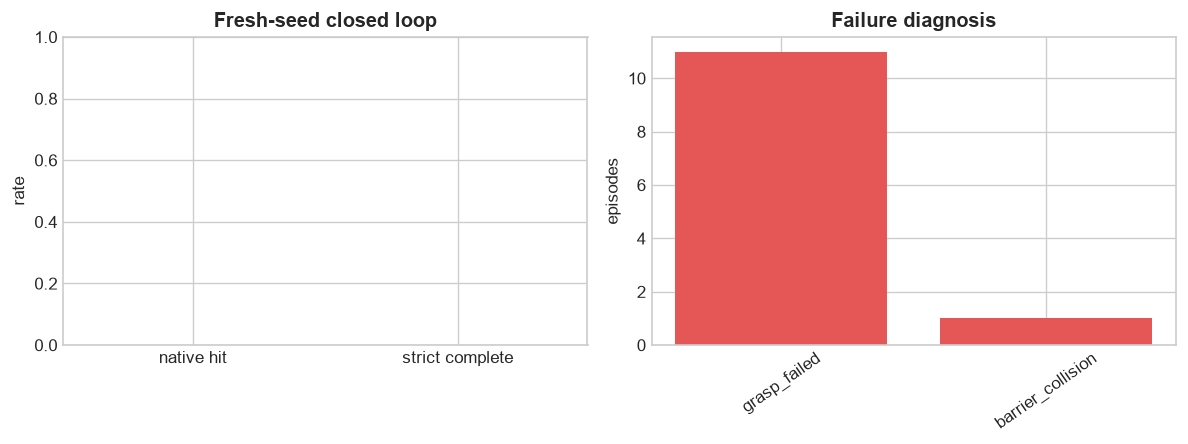

In [32]:
evaluation = evaluate_strict(learned_policy, EVAL_EPISODES)
strict_rate = float(evaluation.strict_successes.mean())
native_rate = float(evaluation.native_hits.mean())

def wilson(successes: int, trials: int, z: float = 1.96) -> tuple[float, float]:
    p = successes / trials
    d = 1 + z*z/trials
    center = (p + z*z/(2*trials)) / d
    margin = z * sqrt(p*(1-p)/trials + z*z/(4*trials*trials)) / d
    return center - margin, center + margin

strict_ci = wilson(int(evaluation.strict_successes.sum()), EVAL_EPISODES)
failures = Counter(classify_failure(info) for info in evaluation.final_infos)
print({
    "native_hits": f"{evaluation.native_hits.sum()}/{EVAL_EPISODES}",
    "strict_successes": f"{evaluation.strict_successes.sum()}/{EVAL_EPISODES}",
    "strict_ci95": strict_ci,
    "failure_types": dict(failures),
})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(["native hit", "strict complete"], [native_rate, strict_rate],
            color=["#F2B84B", "#35C48D"])
axes[0].set(ylim=(0, 1), ylabel="rate", title="Fresh-seed closed loop")
axes[1].bar(failures.keys(), failures.values(), color="#E45756")
axes[1].set(title="Failure diagnosis", ylabel="episodes")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()


In [33]:
class ExpertAsFlatPolicy:
    """Control for E12: the scripted expert behind the flat-vector interface.

    evaluate_strict passes the flat (22,) observation, but the expert consumes the
    raw dict. RobotState.from_raw_obs reads only "observation" (19) and
    "desired_goal" (3), and the flat vector is exactly those two concatenated, so
    the dict can be rebuilt losslessly.
    """

    def __init__(self, config: ExpertConfig | None = None) -> None:
        self.expert = BarrierPickPlaceExpert(config)

    def reset(self) -> None:
        self.expert.reset()

    def __call__(self, observation: np.ndarray) -> np.ndarray:
        flat = np.asarray(observation, dtype=np.float32)
        if flat.shape != (22,):
            raise ValueError(f"Expected a (22,) observation, got {flat.shape}.")
        return self.expert.act({
            "observation": flat[:19],
            "desired_goal": flat[19:22],
        })


expert_control = evaluate_strict(ExpertAsFlatPolicy(), EVAL_EPISODES)

print({
    "expert_strict": f"{int(expert_control.strict_successes.sum())}/{EVAL_EPISODES}",
    "expert_native": f"{int(expert_control.native_hits.sum())}/{EVAL_EPISODES}",
    "learner_strict": f"{int(evaluation.strict_successes.sum())}/{EVAL_EPISODES}",
})
print("expert failures:", dict(Counter(classify_failure(i) for i in expert_control.final_infos)))
print("learner failures:", dict(Counter(classify_failure(i) for i in evaluation.final_infos)))

argv[0]=--background_color_red=0.8745098114013672
argv[1]=--background_color_green=0.21176470816135406
argv[2]=--background_color_blue=0.1764705926179886
{'expert_strict': '9/12', 'expert_native': '10/12', 'learner_strict': '0/12'}
expert failures: {'success': 9, 'unstable_placement': 1, 'dropped_before_barrier': 1, 'grasp_failed': 1}
learner failures: {'grasp_failed': 11, 'barrier_collision': 1}


argv[0]=--background_color_red=0.8745098114013672
argv[1]=--background_color_green=0.21176470816135406
argv[2]=--background_color_blue=0.1764705926179886
argv[0]=--background_color_red=0.8745098114013672
argv[1]=--background_color_green=0.21176470816135406
argv[2]=--background_color_blue=0.1764705926179886


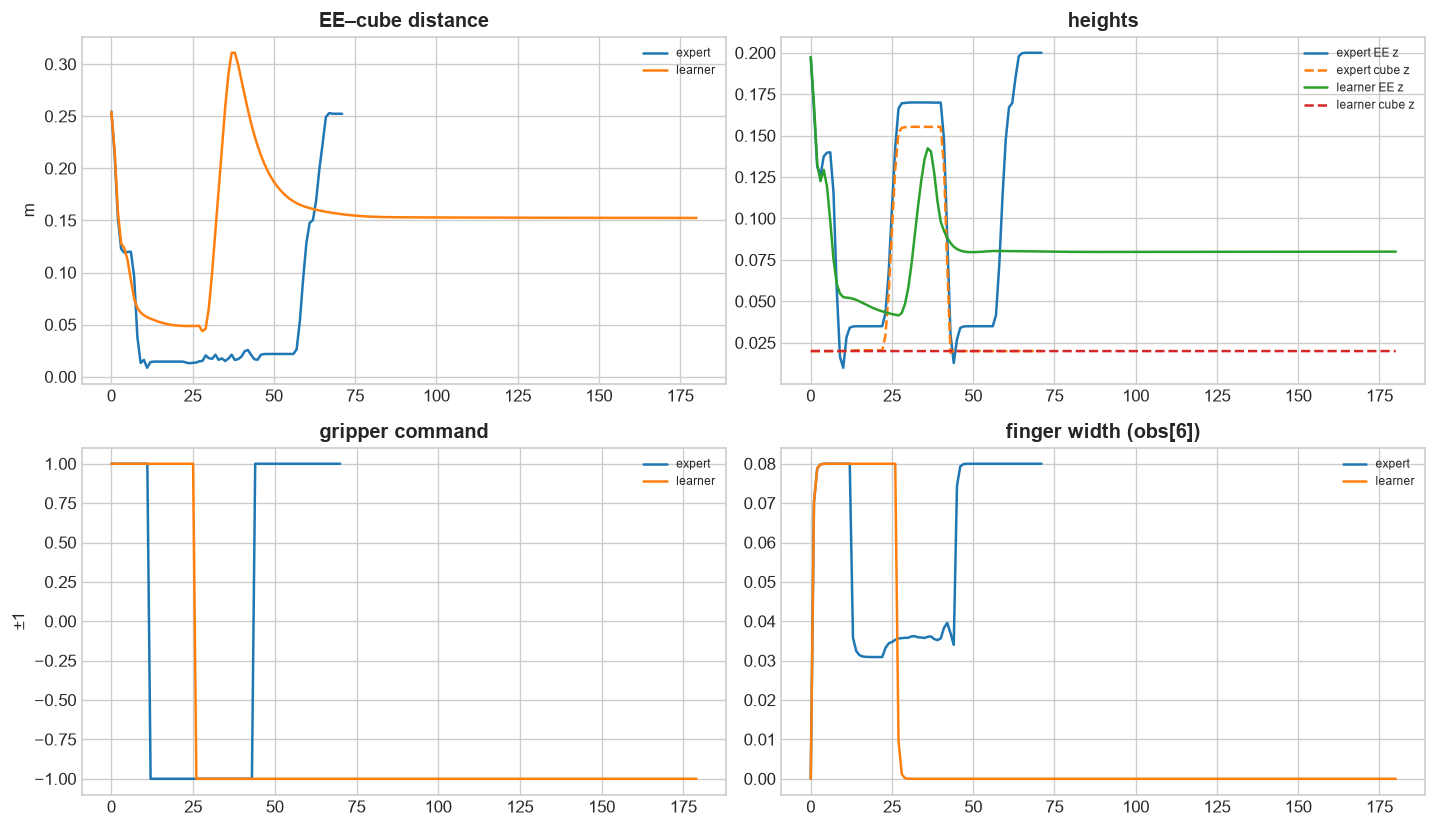

In [35]:
def rollout(policy, seed):
    env = VerifiedPlacementEnv()
    try:
        obs, _ = env.reset(seed=seed)
        if hasattr(policy, "reset"):
            policy.reset()
        observations, actions = [obs], []
        for _ in range(env.config.max_episode_steps):
            action = policy(obs)
            obs, _, terminated, truncated, info = env.step(action)
            observations.append(obs)
            actions.append(action)
            if terminated or truncated:
                break
        return np.asarray(observations), np.asarray(actions), info
    finally:
        env.close()


seed = 10_000
obs_l, act_l, _ = rollout(learned_policy, seed)
obs_e, act_e, _ = rollout(ExpertAsFlatPolicy(), seed)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for obs, act, name in [(obs_e, act_e, "expert"), (obs_l, act_l, "learner")]:
    dist = np.linalg.norm(obs[:, :3] - obs[:, 7:10], axis=1)
    axes[0, 0].plot(dist, label=name)
    axes[0, 1].plot(obs[:, 2], label=f"{name} EE z")
    axes[0, 1].plot(obs[:, 9], "--", label=f"{name} cube z")
    axes[1, 0].plot(act[:, 3], label=name)
    axes[1, 1].plot(obs[:, 6], label=name)
axes[0, 0].set(title="EE–cube distance", ylabel="m")
axes[0, 1].set(title="heights")
axes[1, 0].set(title="gripper command", ylabel="±1")
axes[1, 1].set(title="finger width (obs[6])")
for ax in axes.flat:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [41]:
val_mask = np.isin(data.episode_ids, trained.validation_ids)

model = trained.model
model.eval()
x_val = torch.as_tensor(data.observations[val_mask])
with torch.inference_mode():
    pred_motion, _ = model(x_val)
pred_motion = pred_motion.numpy()
true_motion = data.actions[val_mask][:, :3]

obs_val = data.observations[val_mask]
dist = np.linalg.norm(obs_val[:, 0:3] - obs_val[:, 7:10], axis=1)

bins = [0, 0.02, 0.04, 0.08, 0.15, 0.30]
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (dist >= lo) & (dist < hi)
    if m.sum() == 0:
        continue
    print(f"{lo:.2f}–{hi:.2f} m  n={m.sum():4d}  "
          f"|expert|={np.linalg.norm(true_motion[m], axis=1).mean():.3f}  "
          f"|pred|={np.linalg.norm(pred_motion[m], axis=1).mean():.3f}")

0.00–0.02 m  n= 165  |expert|=0.412  |pred|=0.458
0.02–0.04 m  n= 118  |expert|=0.386  |pred|=0.395
0.04–0.08 m  n=  10  |expert|=0.981  |pred|=0.735
0.08–0.15 m  n=  47  |expert|=0.711  |pred|=0.716
0.15–0.30 m  n=  57  |expert|=0.712  |pred|=0.638


In [42]:
w = data.observations[:, 6]
print("width min:", w.min(), " 1st percentile:", np.quantile(w, 0.01))

width min: 0.0  1st percentile: 0.0


In [43]:
phases_val = np.asarray(data.phases)[val_mask]
pre = np.isin(phases_val, ["approach", "descend"])

xy_true = true_motion[pre][:, :2]
xy_pred = pred_motion[pre][:, :2]
to_cube = (obs_val[pre][:, 7:9] - obs_val[pre][:, 0:2])

def unit(v):
    return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-8)

print("rows:", pre.sum())
print("pred·expert xy alignment:", (unit(xy_pred) * unit(xy_true)).sum(1).mean())
print("pred·toward-cube alignment:", (unit(xy_pred) * unit(to_cube)).sum(1).mean())
print("|xy| expert vs pred:",
      np.linalg.norm(xy_true, axis=1).mean(),
      np.linalg.norm(xy_pred, axis=1).mean())

rows: 72
pred·expert xy alignment: 0.73681116
pred·toward-cube alignment: 0.7386567
|xy| expert vs pred: 0.42796224 0.4776157


In [44]:
zero_w = data.observations[:, 6] < 0.005
d = np.linalg.norm(data.observations[:, 0:3] - data.observations[:, 7:10], axis=1)
print(int(zero_w.sum()), "rows at width≈0")
print(Counter(np.asarray(data.phases)[zero_w]))
print("distance at those rows:", d[zero_w].min(), d[zero_w].max())

23 rows at width≈0
Counter({'approach': 23})
distance at those rows: 0.23620445 0.28222147


In [45]:
big = np.linalg.norm(xy_true, axis=1) > 0.1
print("rows:", int(big.sum()))
print("alignment where xy matters:", (unit(xy_pred[big]) * unit(xy_true[big])).sum(1).mean())

rows: 52
alignment where xy matters: 0.8432818


In [46]:
stall = torch.as_tensor(obs_l[-40:])        # deep in the stall
with torch.inference_mode():
    m_stall, g_stall = model(stall)
print("mean |motion| at stall:", float(m_stall.norm(dim=1).mean()))
print("mean motion xyz:", m_stall.mean(0).numpy())
print("gripper logit:", float(g_stall.mean()))

mean |motion| at stall: 0.0007961451774463058
mean motion xyz: [ 0.001 -0.     0.   ]
gripper logit: -7.199636936187744


## 9. DAgger: change the visited states, not merely the network

Behavior cloning trains on expert-visited states. The learner creates different states after its
first small error. For one failed seed:

1. roll out the learner and save every learner-visited observation;
2. restore or replay each state, then ask the expert for the correct action;
3. append **expert labels**, never the learner's incorrect action;
4. retrain and reevaluate on the unchanged fresh-seed suite.

Use `classify_failure` to choose which state distribution to collect first. If most failures are
`not_released`, prioritize states near the goal rather than simply collecting more approaches.


## 10. Research extensions

Run each comparison with at least three training seeds and the same evaluation seeds:

- demonstrations: `[10, 25, 50, 100, 200]`;
- four-channel MSE versus hybrid regression/classification;
- phase balancing on/off;
- with/without `TEST_GRASP` recovery;
- barrier height curriculum: 4 cm, 6 cm, 8 cm.

Report expert completion, collision rate, minimum crossing clearance, native hit, strict success,
Wilson intervals, and categorized failures. Never report an illustrative number as a result.


## 11. Where every piece belongs in the project

| Notebook concept | Production file |
|---|---|
| strict lifecycle and barrier scene | `src/ilgrasp/sim/verified_task.py` |
| reference 13-phase expert | `src/ilgrasp/experts/verified.py` |
| high-fidelity two-camera recorder | `src/ilgrasp/visualization/recording.py` |
| original observation contract | `src/ilgrasp/sim/observation.py` |
| episode container/rollout | `src/ilgrasp/sim/rollout.py` |
| reusable database layer | `src/ilgrasp/data/database.py` |
| baseline MLP and training | `src/ilgrasp/policies/mlp.py`, `training.py` |
| strict-task tests | `tests/test_verified_task.py` |
| animation CLI | `scripts/record_verified_animation.py` |

The environment monitor never reads the expert's phase. The expert never decides whether the task
succeeded. Keeping those responsibilities independent prevents the teacher from grading itself.


In [34]:
store.close()
print("Closed the SQLite connection. Temporary artifacts:", tutorial_dir)


Closed the SQLite connection. Temporary artifacts: /var/folders/0k/h6cq9ntd0jg2tl0vt221vwbc0000gn/T/verified_expert_lab_vyq6jpgl


## Exit ticket

Explain why these are three different claims:

1. “the cube entered the native 5 cm goal radius”;
2. “the expert completed a collision-free release, retreat, and stability certificate”;
3. “a learned policy repeats that strict task on fresh seeds.”

A complete robotics pipeline defines and measures claim 3. It does not rename claim 1 as success.
